<a href="https://colab.research.google.com/github/samiksha-kamble02/Mitigating-Spurious-Background-Correlations-in-Fine-Grained-Bird-Classification/blob/main/Waterbirds_WILDS_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Waterbirds Project: Spurious Correlations & Group Robustness

1. Environment Setup & Google Drive Persistence
2. Dataset Download & Exploratory Data Analysis (EDA)
3. Data Preprocessing & WILDS DataLoaders
4. Baseline Training: Empirical Risk Minimization (ERM)
5. Debiasing Training: Group DRO (Distributionally Robust Optimization)
6. Subgroup Evaluation & Results Comparison

## 1. Environment Setup & Google Drive Mounting

In [4]:
!pip install -q wilds torch torchvision tqdm pandas matplotlib seaborn

In [5]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
import torchvision.transforms as transforms

from wilds import get_dataset
from wilds.common.data_loaders import get_train_loader, get_eval_loader

# Set deterministic seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

# Configure device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cuda
GPU: Tesla T4


In [6]:
from google.colab import drive
drive.mount('/content/drive')

save_dir = '/content/drive/MyDrive/Waterbirds_Project'
os.makedirs(os.path.join(save_dir, 'checkpoints'), exist_ok=True)
os.makedirs(os.path.join(save_dir, 'results'), exist_ok=True)
print(f"Project directory ready at: {save_dir}")

Mounted at /content/drive
Project directory ready at: /content/drive/MyDrive/Waterbirds_Project


## 2. Dataset Loading & Exploratory Data Analysis (EDA)

In [7]:
# Download and load official WILDS Waterbirds dataset
dataset = get_dataset(dataset="waterbirds", download=True, root_dir="./data")
print(f"Total images in dataset: {len(dataset)}")
print(f"Metadata fields: {dataset.metadata_fields}")

You can also download the dataset manually at https://wilds.stanford.edu/downloads.


489291776Byte [00:07, 61881089.98Byte/s]                             


Extracting ./data/waterbirds_v1.0/archive.tar.gz to ./data/waterbirds_v1.0

It took 0.21 minutes to download and uncompress the dataset.

Total images in dataset: 11788
Metadata fields: ['background', 'y', 'from_source_domain']


Split                         train  val  test
Group                                         
Landbird - Land (Majority)     3498  467  2255
Landbird - Water (Minority)     184  466  2255
Waterbird - Land (Minority)      56  133   642
Waterbird - Water (Majority)   1057  133   642


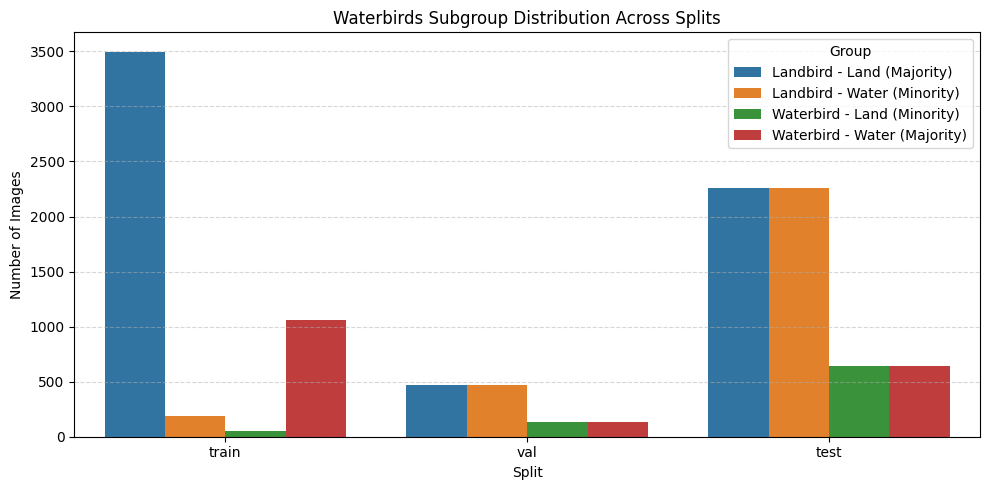

In [8]:
# Inspect subgroup distributions across Train, Validation, and Test splits
split_names = ["train", "val", "test"]
group_labels = {
    (0, 0): "Landbird - Land (Majority)",
    (0, 1): "Landbird - Water (Minority)",
    (1, 0): "Waterbird - Land (Minority)",
    (1, 1): "Waterbird - Water (Majority)"
}

eda_rows = []
for split in split_names:
    subset = dataset.get_subset(split)
    meta = subset.metadata_array.numpy()  # columns: [background, y, from_source]
    bg = meta[:, 0]
    y = meta[:, 1]
    for (bird, place), name in group_labels.items():
        count = int(((y == bird) & (bg == place)).sum())
        eda_rows.append({"Split": split, "Group": name, "Count": count})

eda_df = pd.DataFrame(eda_rows)
pivot_df = eda_df.pivot(index="Group", columns="Split", values="Count")[["train", "val", "test"]]
print(pivot_df)

# Visualize subgroup imbalance
plt.figure(figsize=(10, 5))
sns.barplot(data=eda_df, x="Split", y="Count", hue="Group")
plt.title("Waterbirds Subgroup Distribution Across Splits")
plt.ylabel("Number of Images")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(os.path.join(save_dir, "results", "subgroup_distribution.png"), dpi=200)
plt.show()

## 3. Preprocessing & WILDS DataLoaders

In [9]:
# Standard ImageNet preprocessing for ResNet-50
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_data = dataset.get_subset("train", transform=transform)
val_data = dataset.get_subset("val", transform=transform)
test_data = dataset.get_subset("test", transform=transform)

train_loader = get_train_loader("standard", train_data, batch_size=32)
val_loader = get_eval_loader("standard", val_data, batch_size=64)
test_loader = get_eval_loader("standard", test_data, batch_size=64)

print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)} | Test batches: {len(test_loader)}")

Train batches: 150 | Val batches: 19 | Test batches: 91


## 4. Official WILDS Evaluation Helper

In [10]:
def evaluate_model(model, loader, subset):
    model.eval()
    all_y_pred = []
    all_y_true = []
    all_metadata = []

    with torch.no_grad():
        for x, y_true, metadata in loader:
            x = x.to(device)
            outputs = model(x)
            y_pred = torch.argmax(outputs, dim=1).cpu()

            all_y_pred.append(y_pred)
            all_y_true.append(y_true)
            all_metadata.append(metadata)

    all_y_pred = torch.cat(all_y_pred)
    all_y_true = torch.cat(all_y_true)
    all_metadata = torch.cat(all_metadata)

    bg = all_metadata[:, 0]
    correct = (all_y_pred == all_y_true).float()

    results = {
        "acc_avg": correct.mean().item(),
    }

    group_accs = []
    lines = [f"Average acc: {results['acc_avg']:.4f}"]

    for y_val in [0, 1]:
        for place_val in [0, 1]:
            mask = (all_y_true == y_val) & (bg == place_val)
            acc = correct[mask].mean().item() if mask.sum() > 0 else 0.0
            key = f"acc_y:{y_val}_place:{place_val}"
            results[key] = acc
            group_accs.append(acc)
            lines.append(f"  y = {y_val}, place = {place_val} (n = {int(mask.sum())}): acc = {acc:.4f}")

    results["acc_wg"] = min(group_accs)
    lines.append(f"Worst-group acc: {results['acc_wg']:.4f}")
    results_str = "\n".join(lines)

    return results, results_str

## 5. Baseline Model: Empirical Risk Minimization (ERM)

In [11]:
def train_erm(epochs=15, lr=1e-3, weight_decay=1e-4):
    set_seed(42)
    model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    model.fc = nn.Linear(model.fc.in_features, 2)
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)

    best_val_wg_acc = 0.0
    checkpoint_path = os.path.join(save_dir, "checkpoints", "erm_best.pt")

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0

        for x, y, _ in tqdm(train_loader, desc=f"ERM Epoch {epoch}/{epochs}", leave=False):
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            outputs = model(x)
            loss = criterion(outputs, y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * x.size(0)

        train_loss = running_loss / len(train_data)
        val_results, _ = evaluate_model(model, val_loader, val_data)
        val_avg = val_results["acc_avg"]
        val_wg = val_results["acc_wg"]

        print(f"Epoch {epoch:02d} | Loss: {train_loss:.4f} | Val Avg Acc: {val_avg:.4f} | Val Worst-Group Acc: {val_wg:.4f}")

        if val_wg > best_val_wg_acc:
            best_val_wg_acc = val_wg
            torch.save(model.state_dict(), checkpoint_path)
            print(f"  -> Saved new best ERM model (Val WG Acc: {best_val_wg_acc:.4f})")

    model.load_state_dict(torch.load(checkpoint_path))
    test_results, test_str = evaluate_model(model, test_loader, test_data)
    print("\n=== ERM Test Results ===")
    print(test_str)
    return model, test_results

erm_model, erm_test_results = train_erm(epochs=15)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 176MB/s]


Epoch 01 | Loss: 0.2725 | Val Avg Acc: 0.7264 | Val Worst-Group Acc: 0.2331
  -> Saved new best ERM model (Val WG Acc: 0.2331)


Epoch 02 | Loss: 0.1176 | Val Avg Acc: 0.8157 | Val Worst-Group Acc: 0.3910
  -> Saved new best ERM model (Val WG Acc: 0.3910)


Epoch 03 | Loss: 0.0759 | Val Avg Acc: 0.8407 | Val Worst-Group Acc: 0.5414
  -> Saved new best ERM model (Val WG Acc: 0.5414)


Epoch 04 | Loss: 0.0518 | Val Avg Acc: 0.8532 | Val Worst-Group Acc: 0.5940
  -> Saved new best ERM model (Val WG Acc: 0.5940)


... (7 outputs left out)

Epoch 12 | Loss: 0.0068 | Val Avg Acc: 0.8816 | Val Worst-Group Acc: 0.5639


Epoch 13 | Loss: 0.0046 | Val Avg Acc: 0.8807 | Val Worst-Group Acc: 0.6241


Epoch 14 | Loss: 0.0057 | Val Avg Acc: 0.8682 | Val Worst-Group Acc: 0.6617
  -> Saved new best ERM model (Val WG Acc: 0.6617)


Epoch 15 | Loss: 0.0047 | Val Avg Acc: 0.8724 | Val Worst-Group Acc: 0.6617

=== ERM Test Results ===
Average acc: 0.8788
  y = 0, place = 0 (n = 2255): acc = 0.9969
  y = 0, place = 1 (n = 2255): acc = 0.7951
  y = 1, place = 0 (n = 642): acc = 0.6900
  y = 1, place = 1 (n = 642): acc = 0.9470
Worst-group acc: 0.6900


## 6. Debiasing Model: Group DRO (Distributionally Robust Optimization)

In [12]:
def train_group_dro(epochs=20, lr=1e-4, weight_decay=1e-2, step_size=0.01):
    set_seed(42)
    model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    model.fc = nn.Linear(model.fc.in_features, 2)
    model = model.to(device)

    criterion = nn.CrossEntropyLoss(reduction="none")
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)

    n_groups = 4
    group_weights = torch.ones(n_groups, device=device) / n_groups

    best_val_wg_acc = 0.0
    checkpoint_path = os.path.join(save_dir, "checkpoints", "group_dro_best.pt")

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0

        for x, y, metadata in tqdm(train_loader, desc=f"GroupDRO Epoch {epoch}/{epochs}", leave=False):
            x, y = x.to(device), y.to(device)
            bg = metadata[:, 0].to(device)
            group_idx = 2 * y + bg

            optimizer.zero_grad()
            outputs = model(x)
            per_sample_losses = criterion(outputs, y)

            group_losses = torch.zeros(n_groups, device=device)
            for g in range(n_groups):
                mask = (group_idx == g)
                if mask.sum() > 0:
                    group_losses[g] = per_sample_losses[mask].mean()

            # Exponentiated gradient ascent on group weights
            group_weights = group_weights * torch.exp(step_size * group_losses.detach())
            group_weights = group_weights / group_weights.sum()

            loss = torch.dot(group_weights, group_losses)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * x.size(0)

        train_loss = running_loss / len(train_data)
        val_results, _ = evaluate_model(model, val_loader, val_data)
        val_avg = val_results["acc_avg"]
        val_wg = val_results["acc_wg"]

        print(f"Epoch {epoch:02d} | Loss: {train_loss:.4f} | Val Avg Acc: {val_avg:.4f} | Val Worst-Group Acc: {val_wg:.4f}")

        if val_wg > best_val_wg_acc:
            best_val_wg_acc = val_wg
            torch.save(model.state_dict(), checkpoint_path)
            print(f"  -> Saved new best Group DRO model (Val WG Acc: {best_val_wg_acc:.4f})")

    model.load_state_dict(torch.load(checkpoint_path))
    test_results, test_str = evaluate_model(model, test_loader, test_data)
    print("\n=== Group DRO Test Results ===")
    print(test_str)
    return model, test_results

gdro_model, gdro_test_results = train_group_dro(epochs=20)

Epoch 01 | Loss: 0.4977 | Val Avg Acc: 0.7706 | Val Worst-Group Acc: 0.4436
  -> Saved new best Group DRO model (Val WG Acc: 0.4436)


Epoch 02 | Loss: 0.4560 | Val Avg Acc: 0.8023 | Val Worst-Group Acc: 0.4361


Epoch 03 | Loss: 0.3994 | Val Avg Acc: 0.8090 | Val Worst-Group Acc: 0.4962
  -> Saved new best Group DRO model (Val WG Acc: 0.4962)


Epoch 04 | Loss: 0.3453 | Val Avg Acc: 0.8215 | Val Worst-Group Acc: 0.5038
  -> Saved new best Group DRO model (Val WG Acc: 0.5038)


Epoch 05 | Loss: 0.3060 | Val Avg Acc: 0.8449 | Val Worst-Group Acc: 0.5564
  -> Saved new best Group DRO model (Val WG Acc: 0.5564)


Epoch 06 | Loss: 0.2621 | Val Avg Acc: 0.8482 | Val Worst-Group Acc: 0.5714
  -> Saved new best Group DRO model (Val WG Acc: 0.5714)


... (10 outputs left out)

Epoch 17 | Loss: 0.0880 | Val Avg Acc: 0.8782 | Val Worst-Group Acc: 0.7068


Epoch 18 | Loss: 0.0840 | Val Avg Acc: 0.8857 | Val Worst-Group Acc: 0.7218


Epoch 19 | Loss: 0.0825 | Val Avg Acc: 0.8757 | Val Worst-Group Acc: 0.7218


Epoch 20 | Loss: 0.0738 | Val Avg Acc: 0.8749 | Val Worst-Group Acc: 0.7143

=== Group DRO Test Results ===
Average acc: 0.8728
  y = 0, place = 0 (n = 2255): acc = 0.9725
  y = 0, place = 1 (n = 2255): acc = 0.7738
  y = 1, place = 0 (n = 642): acc = 0.8115
  y = 1, place = 1 (n = 642): acc = 0.9315
Worst-group acc: 0.7738


## 7. Final Comparison & Export Results

                       Metric  ERM (Baseline)  Group DRO
             Average Accuracy        0.878840   0.872799
         Worst-Group Accuracy        0.690031   0.773836
  Landbird on Land (Majority)        0.996896   0.972506
 Landbird on Water (Minority)        0.795122   0.773836
 Waterbird on Land (Minority)        0.690031   0.811526
Waterbird on Water (Majority)        0.947040   0.931464

Saved comparison results to: /content/drive/MyDrive/Waterbirds_Project/results/waterbirds_comparison.csv


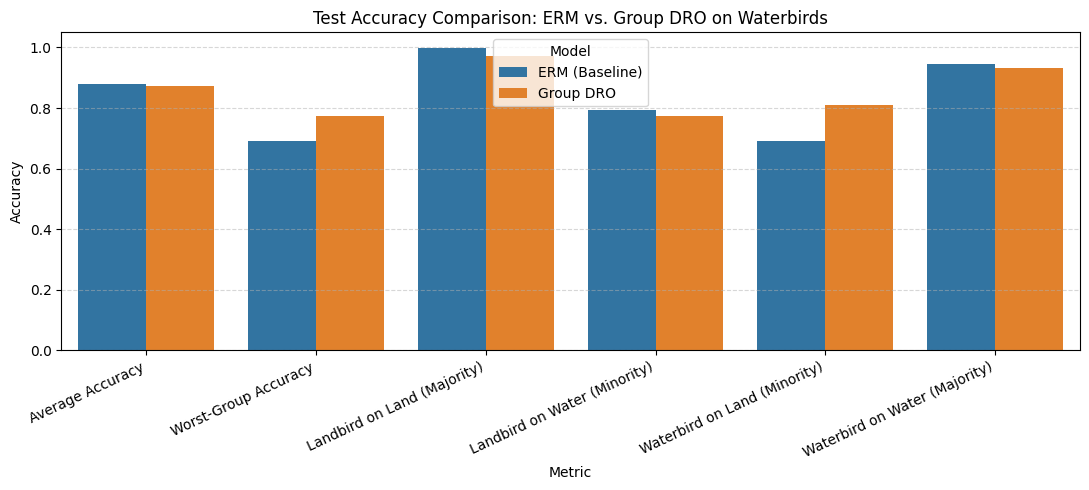

In [13]:
metrics_to_compare = [
    "acc_avg",
    "acc_wg",
    "acc_y:0_place:0",
    "acc_y:0_place:1",
    "acc_y:1_place:0",
    "acc_y:1_place:1",
]

comparison_df = pd.DataFrame({
    "Metric": [
        "Average Accuracy",
        "Worst-Group Accuracy",
        "Landbird on Land (Majority)",
        "Landbird on Water (Minority)",
        "Waterbird on Land (Minority)",
        "Waterbird on Water (Majority)",
    ],
    "ERM (Baseline)": [erm_test_results[m] for m in metrics_to_compare],
    "Group DRO": [gdro_test_results[m] for m in metrics_to_compare],
})

print(comparison_df.to_string(index=False))
csv_path = os.path.join(save_dir, "results", "waterbirds_comparison.csv")
comparison_df.to_csv(csv_path, index=False)
print(f"\nSaved comparison results to: {csv_path}")

# Plot ERM vs Group DRO comparison
plot_df = comparison_df.melt(id_vars="Metric", var_name="Model", value_name="Accuracy")
plt.figure(figsize=(11, 5))
sns.barplot(data=plot_df, x="Metric", y="Accuracy", hue="Model")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 1.05)
plt.title("Test Accuracy Comparison: ERM vs. Group DRO on Waterbirds")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plot_path = os.path.join(save_dir, "results", "erm_vs_groupdro.png")
plt.savefig(plot_path, dpi=200)
plt.show()

Found 3 contrasting minority-group examples.


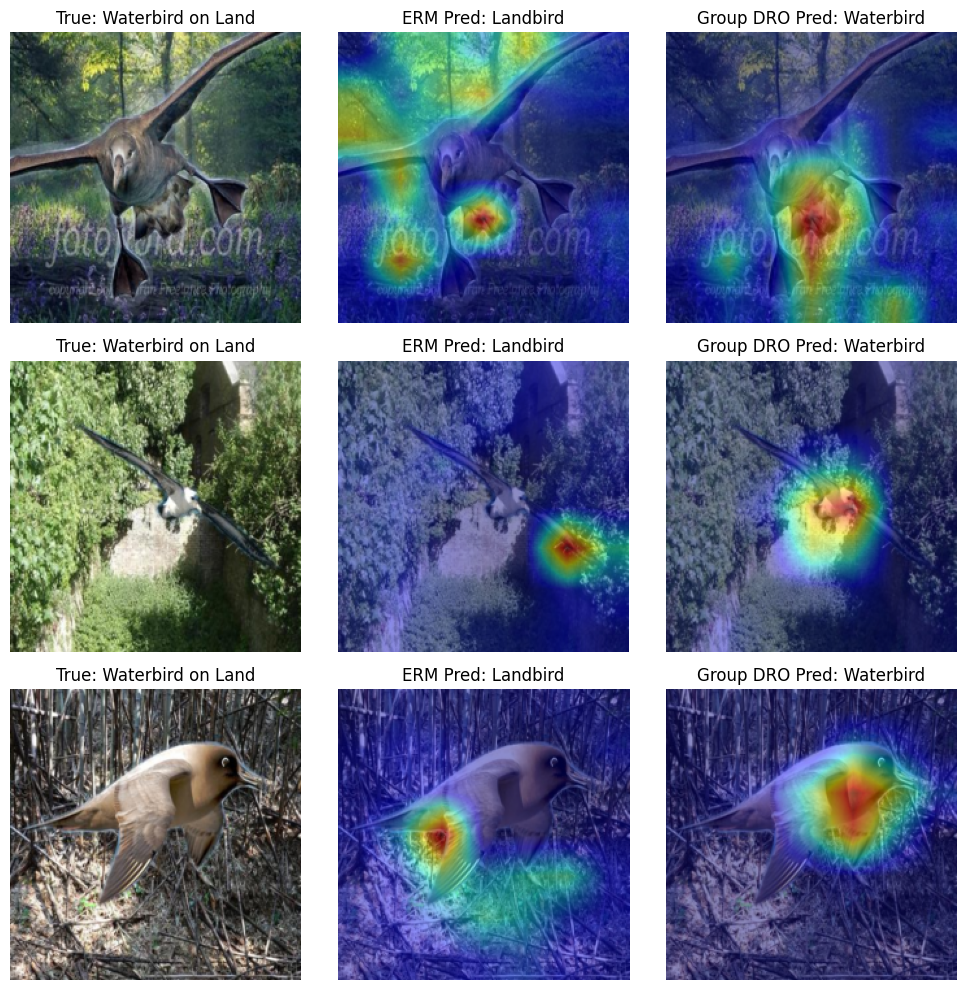

In [17]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self.fwd_handle = target_layer.register_forward_hook(self.save_activation)
        self.bwd_handle = target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output.detach()

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def remove_hooks(self):
        self.fwd_handle.remove()
        self.bwd_handle.remove()

    def generate(self, input_tensor, target_class=None):
        self.model.eval()
        output = self.model(input_tensor)
        actual_pred = output.argmax(dim=1).item()
        if target_class is None:
            target_class = actual_pred

        self.model.zero_grad()
        output[0, target_class].backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = torch.relu(cam).squeeze().cpu().numpy()
        cam = cv2.resize(cam, (224, 224))
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, actual_pred

erm_cam = GradCAM(erm_model, erm_model.layer4[-1])
gdro_cam = GradCAM(gdro_model, gdro_model.layer4[-1])

examples_found = 0
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
label_names = ["Landbird", "Waterbird"]
bg_names = ["Land", "Water"]

for x, y, meta in test_data:
    true_y = y.item()
    bg = meta[0].item()

    # Focus on minority groups (y != bg): Waterbird on Land or Landbird on Water
    if true_y != bg:
        inp = x.unsqueeze(0).to(device)
        # Generate Grad-CAM for each model's actual predicted class
        hm_erm, pred_erm = erm_cam.generate(inp)
        hm_gdro, pred_gdro = gdro_cam.generate(inp)

        # Pick cases where ERM fails (fooled by background) and Group DRO succeeds
        if pred_erm != true_y and pred_gdro == true_y:
            orig_img = unnormalize(x)
            axes[examples_found, 0].imshow(orig_img)
            axes[examples_found, 0].set_title(f"True: {label_names[true_y]} on {bg_names[bg]}")
            axes[examples_found, 0].axis("off")

            axes[examples_found, 1].imshow(orig_img)
            axes[examples_found, 1].imshow(hm_erm, cmap="jet", alpha=0.45)
            axes[examples_found, 1].set_title(f"ERM Pred: {label_names[pred_erm]}")
            axes[examples_found, 1].axis("off")

            axes[examples_found, 2].imshow(orig_img)
            axes[examples_found, 2].imshow(hm_gdro, cmap="jet", alpha=0.45)
            axes[examples_found, 2].set_title(f"Group DRO Pred: {label_names[pred_gdro]}")
            axes[examples_found, 2].axis("off")

            examples_found += 1
            if examples_found == 3:
                break

erm_cam.remove_hooks()
gdro_cam.remove_hooks()

print(f"Found {examples_found} contrasting minority-group examples.")
plt.tight_layout()
plt.savefig(os.path.join(save_dir, "results", "gradcam_comparison.png"), dpi=200)
plt.show()

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm
import numpy as np
import torch
import torch.nn as nn

def extract_features(model, loader, desc="Extracting"):
    model.eval()
    backbone = nn.Sequential(*list(model.children())[:-1]).to(device)
    feats, labels, bgs = [], [], []
    with torch.no_grad():
        for x, y, meta in tqdm(loader, desc=desc):
            f = backbone(x.to(device)).flatten(1).cpu().numpy()
            feats.append(f)
            labels.append(y.numpy())
            bgs.append(meta[:, 0].numpy())
    return np.concatenate(feats), np.concatenate(labels), np.concatenate(bgs)

val_feats, val_y, val_bg = extract_features(erm_model, val_loader, "Val Features")
test_feats, test_y, test_bg = extract_features(erm_model, test_loader, "Test Features")

# Standardize features so LogisticRegression converges in <1 second
scaler = StandardScaler()
val_feats_scaled = scaler.fit_transform(val_feats)
test_feats_scaled = scaler.transform(test_feats)

# Create a group-balanced subset from validation features
min_group_size = min(
    ((val_y == y) & (val_bg == bg)).sum()
    for y in [0, 1] for bg in [0, 1]
)

bal_idx = []
rng = np.random.default_rng(42)
for y in [0, 1]:
    for bg in [0, 1]:
        idx = np.where((val_y == y) & (val_bg == bg))[0]
        bal_idx.extend(rng.choice(idx, size=min_group_size, replace=False))

# Retrain last layer with L1-regularized Logistic Regression (with max_iter cap)
clf = LogisticRegression(penalty="l1", C=1.0, solver="liblinear", max_iter=500, random_state=42)
clf.fit(val_feats_scaled[bal_idx], val_y[bal_idx])
dfr_preds = clf.predict(test_feats_scaled)

print("\n=== DFR Test Accuracies ===")
group_accs = []
for y in [0, 1]:
    for bg in [0, 1]:
        mask = (test_y == y) & (test_bg == bg)
        acc = (dfr_preds[mask] == test_y[mask]).mean()
        group_accs.append(acc)
        print(f"y={y}, place={bg}: {acc:.4f}")

print(f"Average Acc: {(dfr_preds == test_y).mean():.4f}")
print(f"Worst-Group Acc: {min(group_accs):.4f}")

Test Features: 100%|██████████| 91/91 [00:43<00:00,  2.07it/s]



=== DFR Test Accuracies ===
y=0, place=0: 0.9033
y=0, place=1: 0.8882
y=1, place=0: 0.8894
y=1, place=1: 0.9128
Average Acc: 0.8970
Worst-Group Acc: 0.8882


                       Metric  ERM (Baseline)  Group DRO  DFR (Last-Layer Retrain)
             Average Accuracy        0.878840   0.872799                  0.896962
         Worst-Group Accuracy        0.690031   0.773836                  0.888248
  Landbird on Land (Majority)        0.996896   0.972506                  0.903326
 Landbird on Water (Minority)        0.795122   0.773836                  0.888248
 Waterbird on Land (Minority)        0.690031   0.811526                  0.889408
Waterbird on Water (Majority)        0.947040   0.931464                  0.912773

Saved 3-way comparison CSV to: /content/drive/MyDrive/Waterbirds_Project/results/waterbirds_final_3way_comparison.csv


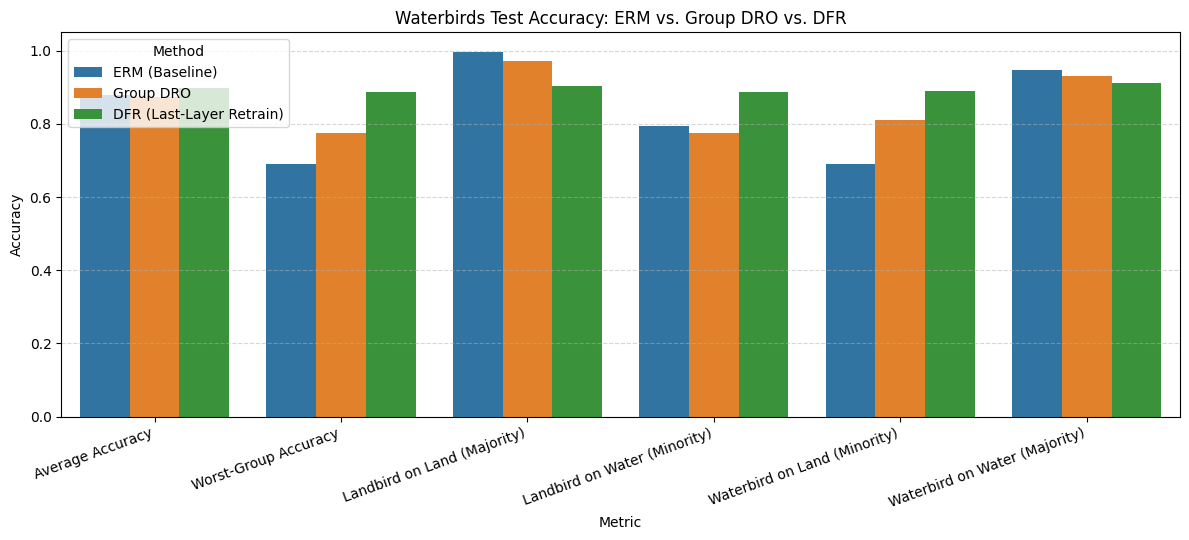

In [19]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Re-evaluate ERM and Group DRO if needed (in case runtime restarted earlier)
erm_test_results, _ = evaluate_model(erm_model, test_loader, test_data)
gdro_test_results, _ = evaluate_model(gdro_model, test_loader, test_data)

# Store DFR metrics in the same dictionary format
dfr_test_results = {
    "acc_avg": float((dfr_preds == test_y).mean()),
    "acc_wg": float(min(group_accs)),
    "acc_y:0_place:0": float((dfr_preds[(test_y == 0) & (test_bg == 0)] == 0).mean()),
    "acc_y:0_place:1": float((dfr_preds[(test_y == 0) & (test_bg == 1)] == 0).mean()),
    "acc_y:1_place:0": float((dfr_preds[(test_y == 1) & (test_bg == 0)] == 1).mean()),
    "acc_y:1_place:1": float((dfr_preds[(test_y == 1) & (test_bg == 1)] == 1).mean()),
}

metrics_to_compare = [
    "acc_avg",
    "acc_wg",
    "acc_y:0_place:0",
    "acc_y:0_place:1",
    "acc_y:1_place:0",
    "acc_y:1_place:1",
]

final_df = pd.DataFrame({
    "Metric": [
        "Average Accuracy",
        "Worst-Group Accuracy",
        "Landbird on Land (Majority)",
        "Landbird on Water (Minority)",
        "Waterbird on Land (Minority)",
        "Waterbird on Water (Majority)",
    ],
    "ERM (Baseline)": [erm_test_results[m] for m in metrics_to_compare],
    "Group DRO": [gdro_test_results[m] for m in metrics_to_compare],
    "DFR (Last-Layer Retrain)": [dfr_test_results[m] for m in metrics_to_compare],
})

print(final_df.to_string(index=False))

# Save final 3-way comparison table
final_csv_path = os.path.join(save_dir, "results", "waterbirds_final_3way_comparison.csv")
final_df.to_csv(final_csv_path, index=False)
print(f"\nSaved 3-way comparison CSV to: {final_csv_path}")

# Plot 3-way grouped bar chart
plot_df = final_df.melt(id_vars="Metric", var_name="Method", value_name="Accuracy")
plt.figure(figsize=(12, 5.5))
sns.barplot(data=plot_df, x="Metric", y="Accuracy", hue="Method")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1.05)
plt.title("Waterbirds Test Accuracy: ERM vs. Group DRO vs. DFR")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()

final_plot_path = os.path.join(save_dir, "results", "waterbirds_3way_comparison.png")
plt.savefig(final_plot_path, dpi=200)
plt.show()